# EDA: Customer Churn (Telco)

**Autor:** Bryan Abreu · **Fecha:** 22 de noviembre de 2026 · **Equipo:** Limpieza y EDA · **Rama:** `cleaning-eda`

**Objetivo:** entender qué factores se relacionan con el abandono de clientes (`Churn`) y sacar los hallazgos principales para el equipo de Modelos, la página web (Hallazgos) y el dashboard de Power BI.

> La limpieza oficial la hace el script `src/cleaning/clean_data.py`, que genera `data/processed/telco_churn_clean.csv`. Este notebook parte de `data/raw/`, aplica la misma limpieza y, en la sección 3, comprueba que su resultado es idéntico al del script.

Las celdas marcadas como **Nota de Bryan (criterio)** son decisiones o propuestas mías. Las dejo explicadas para que el equipo las revise y diga si está de acuerdo o propone otra cosa.

## Contenido
0. Librerías y configuración
1. Verificación: ¿es la data correcta?
2. Carga y vista general
3. Calidad de datos
4. Variable objetivo
5. Análisis univariado
6. Churn por variable categórica
7. Variables numéricas contra churn
8. Segmentos de alto riesgo
9. Impacto en ingresos
10. Conclusiones y propuestas para el equipo

## 0. Librerías y configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Estilo de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", None)

# Paleta común propuesta por el equipo Web (azul, y verde/rojo para No/Sí churn)
BLUE = "#0071e3"
CHURN_COLORS = {"No": "#34c759", "Yes": "#ff3b30"}

# Rutas: el notebook vive en notebooks/, los datos en data/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

## 1. Verificación: ¿es la data correcta?

Antes de analizar, comprobamos que estamos usando **la misma data que define el proyecto** y que tiene la forma que esperan los otros equipos. Cada revisión usa `assert`: si algo no cuadra, el notebook se detiene con un error y no seguimos con datos equivocados.

Las referencias salen de los documentos del repo:
- **README**, sección *Dataset*: el archivo, 7,043 filas y 21 columnas.
- **README**, *Contrato API → Web*: los 19 campos con sus valores permitidos y las reglas de coherencia.
- **docs/plan-api-web.md**: las cifras preliminares (26.5% de churn, US$139,131 al mes, etc.).

In [2]:
raw_df = pd.read_csv(RAW_PATH)

# 1) Archivo, filas y columnas que indica el README
assert RAW_PATH.name == "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert raw_df.shape == (7043, 21), raw_df.shape

# 2) Las columnas del contrato con la API (19 campos) + customerID + Churn
API_FIELDS = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges",
]
assert list(raw_df.columns) == ["customerID"] + API_FIELDS + ["Churn"]

# 3) Valores permitidos según el contrato
YES_NO = {"Yes", "No"}
INTERNET_EXTRAS = {"Yes", "No", "No internet service"}
ALLOWED = {
    "gender": {"Female", "Male"},
    "SeniorCitizen": {0, 1},
    "Partner": YES_NO, "Dependents": YES_NO, "PhoneService": YES_NO,
    "PaperlessBilling": YES_NO, "Churn": YES_NO,
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "OnlineSecurity": INTERNET_EXTRAS, "OnlineBackup": INTERNET_EXTRAS,
    "DeviceProtection": INTERNET_EXTRAS, "TechSupport": INTERNET_EXTRAS,
    "StreamingTV": INTERNET_EXTRAS, "StreamingMovies": INTERNET_EXTRAS,
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaymentMethod": {"Electronic check", "Mailed check",
                      "Bank transfer (automatic)", "Credit card (automatic)"},
}
for col, allowed in ALLOWED.items():
    extra = set(raw_df[col].unique()) - allowed
    assert not extra, f"{col} tiene valores fuera del contrato: {extra}"
assert (raw_df["tenure"] >= 0).all()
assert (raw_df["MonthlyCharges"] > 0).all()

# 4) Reglas de coherencia del contrato
no_phone = raw_df["PhoneService"] == "No"
assert (raw_df.loc[no_phone, "MultipleLines"] == "No phone service").all()
assert (raw_df.loc[~no_phone, "MultipleLines"] != "No phone service").all()
no_internet = raw_df["InternetService"] == "No"
internet_extras = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]
assert (raw_df.loc[no_internet, internet_extras] == "No internet service").all().all()
assert (raw_df.loc[~no_internet, internet_extras] != "No internet service").all().all()
assert not (no_phone & no_internet).any(), "Hay clientes sin teléfono ni internet"

print("OK: el archivo, las columnas, los valores y las reglas coinciden con el README y el contrato de la API.")

OK: el archivo, las columnas, los valores y las reglas coinciden con el README y el contrato de la API.


> **Nota de Bryan (criterio):** Pienso que esta verificación debe quedarse al inicio de todos los notebooks y también del script de limpieza, porque es la forma de demostrar que trabajamos con la data oficial del proyecto (la que está en `data/raw/` del repo, que nadie modifica) y no con una copia distinta. Si alguien cambia el archivo por error, el notebook falla aquí y no al final. Al terminar el EDA también comparo mis cifras con las del plan del equipo Web (sección 10), para confirmar que los cálculos están bien.

## 2. Carga y vista general

In [3]:
print(f"Filas: {raw_df.shape[0]:,} · Columnas: {raw_df.shape[1]}")
raw_df.head()

Filas: 7,043 · Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Valores únicos por columna: ayuda a separar categóricas de numéricas
raw_df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

## 3. Calidad de datos

In [6]:
# Duplicados
print("Filas duplicadas:", raw_df.duplicated().sum())
print("customerID duplicados:", raw_df["customerID"].duplicated().sum())

# Nulos (pandas no detecta los espacios en blanco como nulos)
raw_df.isna().sum().sum()

Filas duplicadas: 0
customerID duplicados: 0


np.int64(0)

`TotalCharges` aparece como texto (`object`), aunque debería ser numérico. Revisamos qué valores no se pueden convertir.

In [7]:
total_numeric = pd.to_numeric(raw_df["TotalCharges"], errors="coerce")
blank_rows = raw_df[total_numeric.isna()]
print("Valores no numéricos en TotalCharges:", len(blank_rows))
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valores no numéricos en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Los clientes con `TotalCharges` vacío tienen **`tenure` = 0**: son clientes nuevos que todavía no han pagado nada.

> **Nota de Bryan (criterio):** Pienso que los 11 `TotalCharges` vacíos se deben llenar con **0** y no borrar las filas. Según yo es mejor para el proceso por tres razones: (1) son clientes reales que acaban de entrar, no errores; (2) la API va a recibir clientes nuevos con `tenure` 0 y el contrato ya dice que en ese caso se envía `TotalCharges = 0`, así que el modelo debe aprender con ese mismo caso; y (3) son solo 11 filas, pero borrarlas no aporta nada. Es la misma propuesta del equipo Web, así que quedaríamos alineados.

In [8]:
df = raw_df.copy()
# Convertimos el cargo total a número; los vacíos (tenure 0) quedan en 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Variable objetivo en 0/1 para calcular tasas con .mean()
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

# SeniorCitizen viene como 0/1; la pasamos a texto para graficarla como categórica
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df.dtypes

customerID              str
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
churn_flag            int64
dtype: object

> **Nota de Bryan (criterio):** Los cambios de esta celda (`churn_flag` y `SeniorCitizen` como texto) son **solo para el análisis**. Pienso que el CSV limpio de `data/processed/` debe mantener las columnas con los mismos nombres y valores del dataset original (`SeniorCitizen` en 0/1, `Churn` en Yes/No), porque el contrato de la API y el Pipeline del equipo de Modelos esperan las columnas originales. Si cambiamos formatos en la limpieza, obligamos a los otros equipos a adaptar su código.

In [9]:
# El resultado del notebook debe ser idéntico al CSV oficial que genera el script de limpieza
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_clean.csv"
processed_df = pd.read_csv(PROCESSED_PATH)
pd.testing.assert_frame_equal(processed_df, raw_df.assign(TotalCharges=df["TotalCharges"]))
print("OK: la limpieza del notebook es igual a data/processed/telco_churn_clean.csv")

OK: la limpieza del notebook es igual a data/processed/telco_churn_clean.csv


In [10]:
# Coherencia: TotalCharges debería parecerse a tenure × MonthlyCharges
expected_total = df["tenure"] * df["MonthlyCharges"]
ratio = (df["TotalCharges"] / expected_total).replace([np.inf, -np.inf], np.nan)
ratio.describe()

count    7032.000000
mean        1.000275
std         0.051159
min         0.689356
25%         0.979546
50%         1.000000
75%         1.019562
max         1.573454
dtype: float64

La razón mediana es 1.00 y casi todos los valores están entre 0.98 y 1.02: el cargo total cuadra con la antigüedad por el cargo mensual. Las pequeñas diferencias se explican porque el cargo mensual pudo cambiar con el tiempo.

## 4. Variable objetivo: `Churn`

,clientes,porcentaje
Churn,,
No,5174,73.5
Yes,1869,26.5


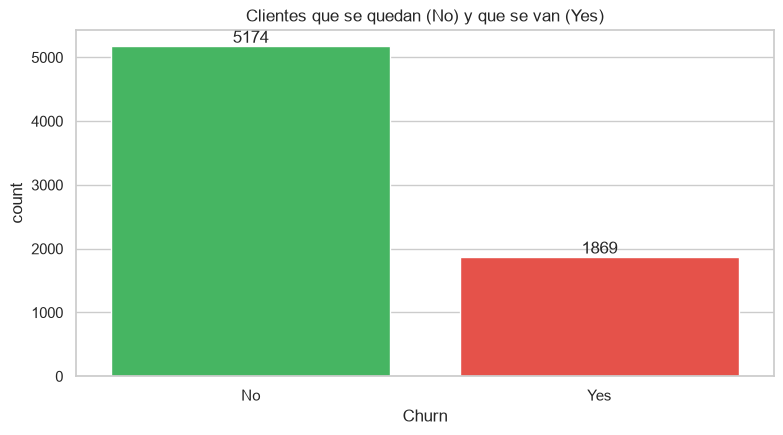

In [11]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"clientes": churn_counts, "porcentaje": churn_pct}))

ax = sns.countplot(data=df, x="Churn", hue="Churn", palette=CHURN_COLORS, legend=False)
ax.bar_label(ax.containers[0]); ax.bar_label(ax.containers[1])
ax.set_title("Clientes que se quedan (No) y que se van (Yes)")
plt.show()

Las clases están **desbalanceadas**: aproximadamente 3 clientes se quedan por cada 1 que se va.

> **Nota de Bryan (criterio):** Pienso que el equipo de Modelos no debe medir el modelo solo con *accuracy*, porque un modelo que diga "nadie se va" ya acierta el 73.5% y no sirve para nada. Según yo es mejor dividir train/test con `stratify=y` (para que los dos tengan 26.5% de churn) y fijarse en el **recall** de la clase "Yes", porque para el negocio es peor no detectar a un cliente que se va que llamar a uno que se iba a quedar.

## 5. Análisis univariado

In [12]:
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
df[NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


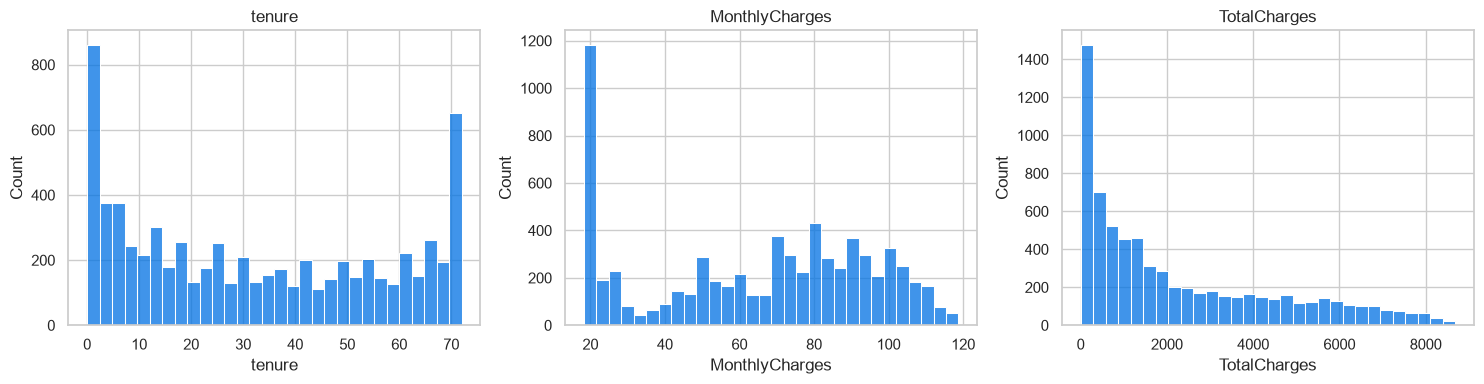

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(df[col], bins=30, ax=ax, color=BLUE)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [14]:
CATEGORICAL_COLS = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
for col in CATEGORICAL_COLS:
    print(df[col].value_counts().to_string(), "\n")

gender
Male      3555
Female    3488 

SeniorCitizen
No     5901
Yes    1142 

Partner
No     3641
Yes    3402 

Dependents
No     4933
Yes    2110 

PhoneService
Yes    6361
No      682 

MultipleLines
No                  3390
Yes                 2971
No phone service     682 

InternetService
Fiber optic    3096
DSL            2421
No             1526 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526 

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526 

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526 

TechSupport
No                     3473
Yes                    2044
No internet service    1526 

StreamingTV
No                     2810
Yes                    2707
No internet service    1526 

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526 

Contract
Month-to-month    3875
Two year 

> **Nota de Bryan (criterio):** Los valores "No internet service" y "No phone service" se repiten en varias columnas (1,526 y 682 clientes). Pienso que en el CSV limpio **no** debemos cambiarlos por "No", porque el contrato de la API los usa tal cual y porque guardan información distinta: "No" es que tiene internet pero no contrató el servicio, y "No internet service" es que ni siquiera tiene internet. Si Modelos quiere simplificarlos, que lo haga dentro de su Pipeline.

## 6. Churn por variable categórica

Para cada variable calculamos la **tasa de churn** de cada grupo. La línea punteada es el promedio general.

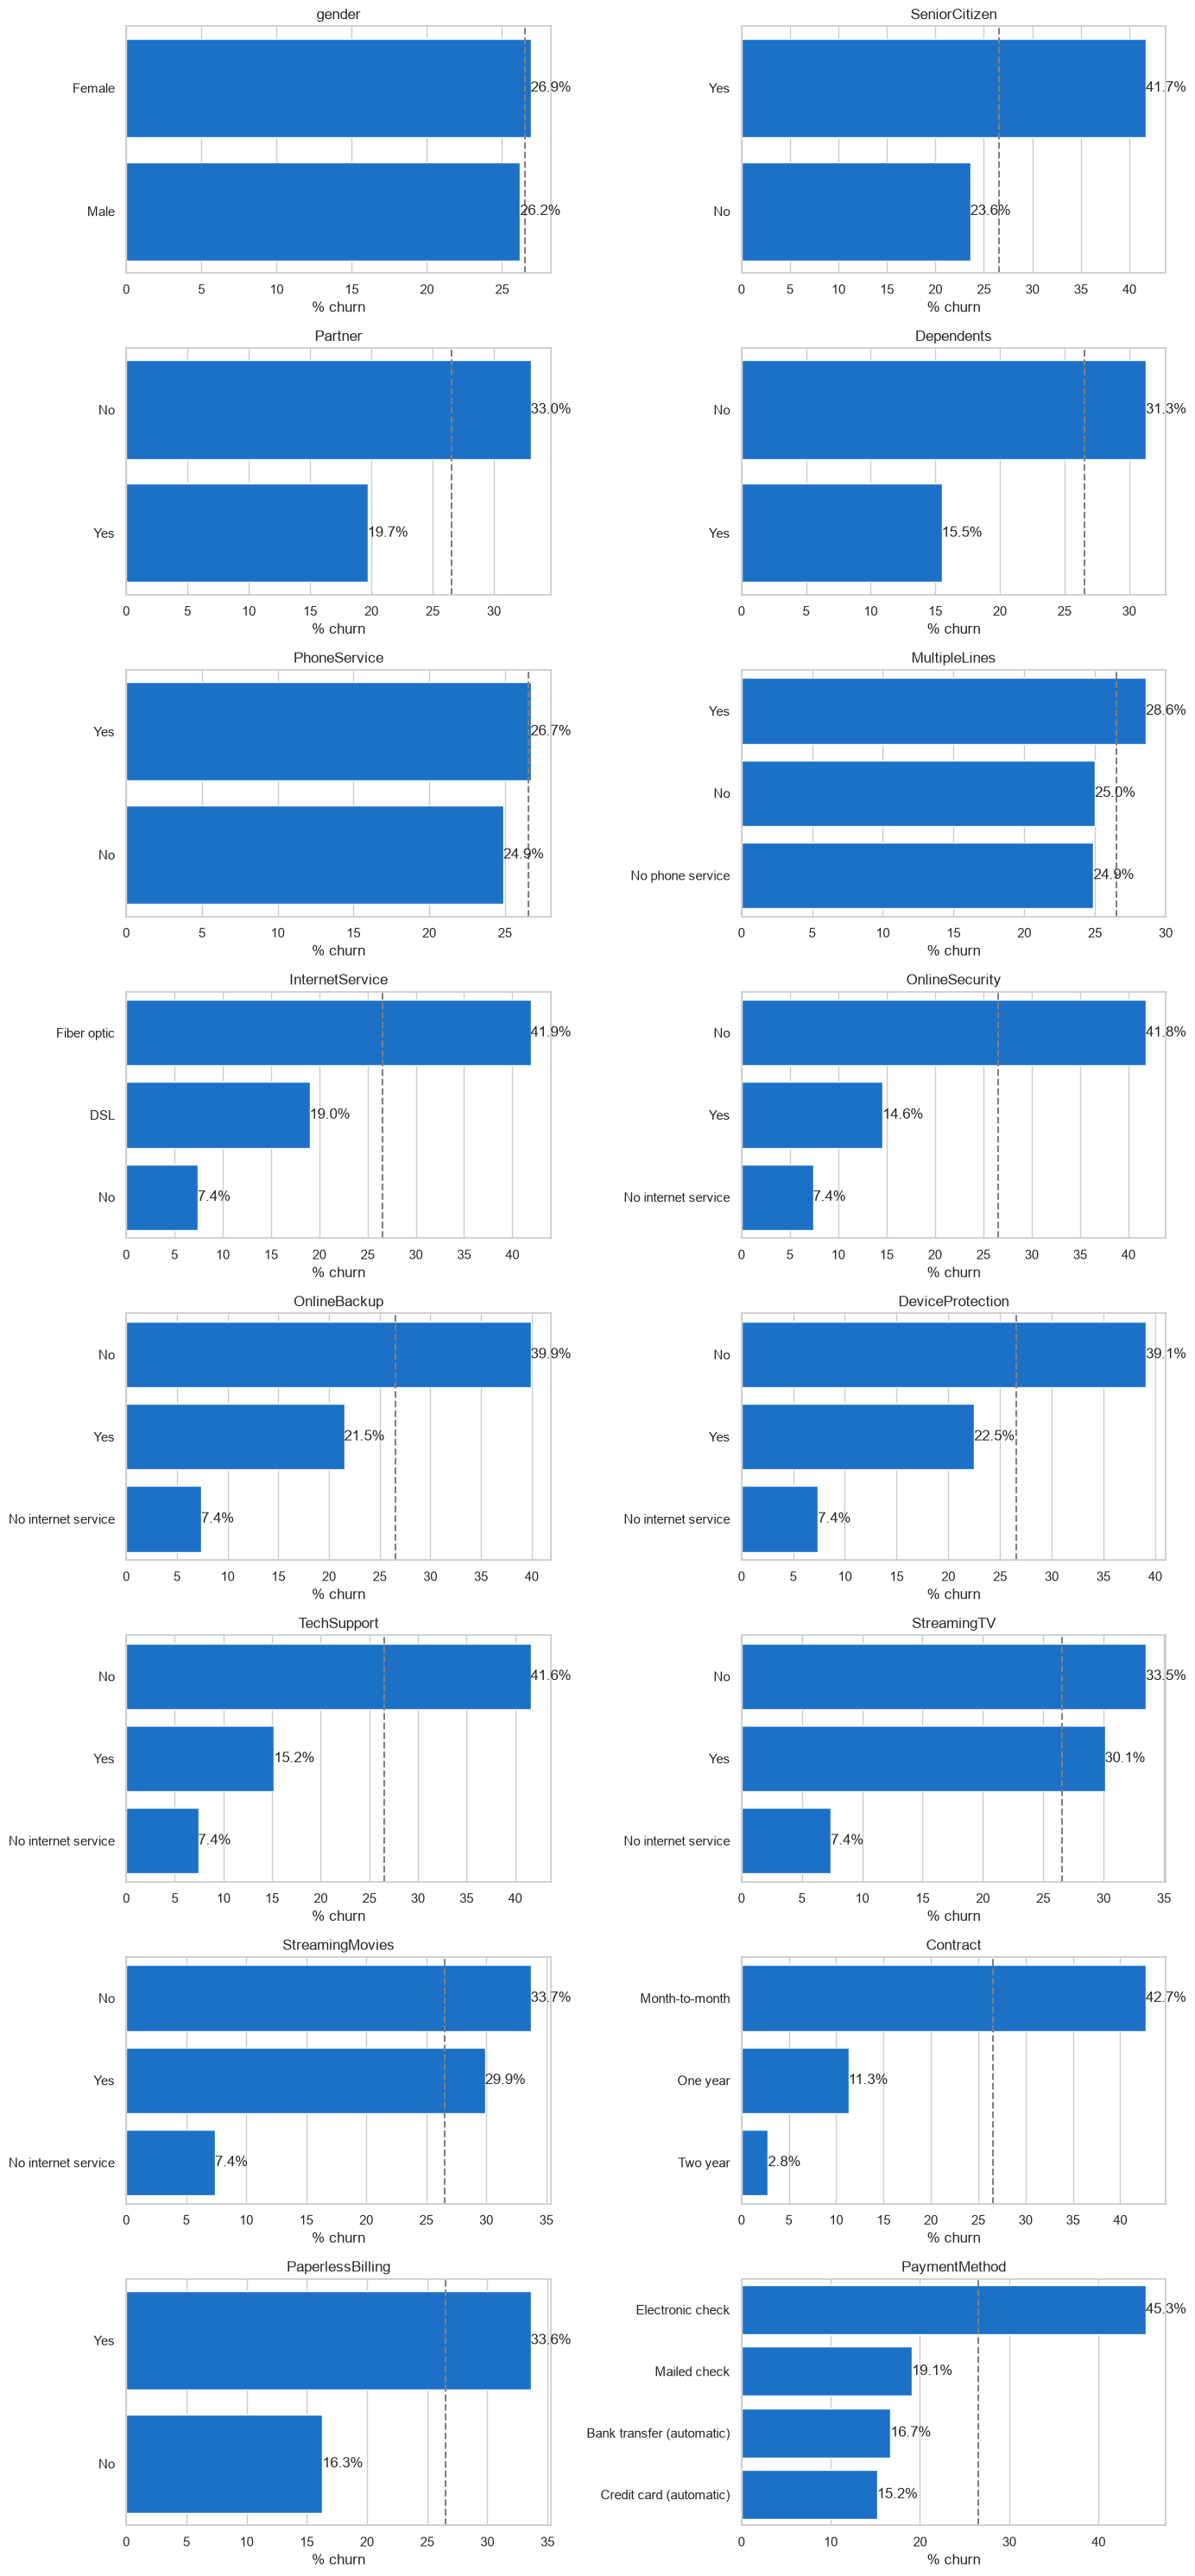

In [15]:
overall_rate = df["churn_flag"].mean()

def churn_rate_by(column):
    """Devuelve clientes y tasa de churn (%) por cada valor de la columna."""
    summary = df.groupby(column, observed=True)["churn_flag"].agg(clientes="size", churn_rate="mean")
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(1)
    return summary.sort_values("churn_rate", ascending=False)

def plot_churn_rate(column, ax):
    summary = churn_rate_by(column)
    sns.barplot(x=summary["churn_rate"], y=summary.index.astype(str), ax=ax, color=BLUE)
    ax.axvline(overall_rate * 100, ls="--", color="gray")
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_title(column); ax.set_xlabel("% churn"); ax.set_ylabel("")

fig, axes = plt.subplots(8, 2, figsize=(14, 30))
for ax, col in zip(axes.flat, CATEGORICAL_COLS):
    plot_churn_rate(col, ax)
plt.tight_layout()
plt.show()

In [16]:
# Ranking: qué variables separan más el churn (diferencia entre el grupo más alto y el más bajo)
spread = {col: churn_rate_by(col)["churn_rate"].max() - churn_rate_by(col)["churn_rate"].min()
          for col in CATEGORICAL_COLS}
pd.Series(spread, name="diferencia_puntos_%").sort_values(ascending=False)

Contract            39.9
InternetService     34.5
OnlineSecurity      34.4
TechSupport         34.2
OnlineBackup        32.5
DeviceProtection    31.7
PaymentMethod       30.1
StreamingMovies     26.3
StreamingTV         26.1
SeniorCitizen       18.1
PaperlessBilling    17.3
Dependents          15.8
Partner             13.3
MultipleLines        3.7
PhoneService         1.8
gender               0.7
Name: diferencia_puntos_%, dtype: float64

> **Nota de Bryan (criterio):** `gender`, `PhoneService` y `MultipleLines` casi no cambian la tasa de churn (menos de 4 puntos de diferencia). Aun así, pienso que **no** debemos borrarlas del CSV limpio: la limpieza no es el lugar para decidir qué variables usa el modelo, y la API recibe los 19 campos. Mi propuesta es pasarle este ranking al equipo de Modelos como sugerencia para que ellos decidan con sus métricas.

In [17]:
churn_rate_by("Contract")

,clientes,churn_rate
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


In [18]:
churn_rate_by("PaymentMethod")

,clientes,churn_rate
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


In [19]:
churn_rate_by("InternetService")

,clientes,churn_rate
InternetService,,
Fiber optic,3096,41.9
DSL,2421,19.0
No,1526,7.4


## 7. Variables numéricas contra churn

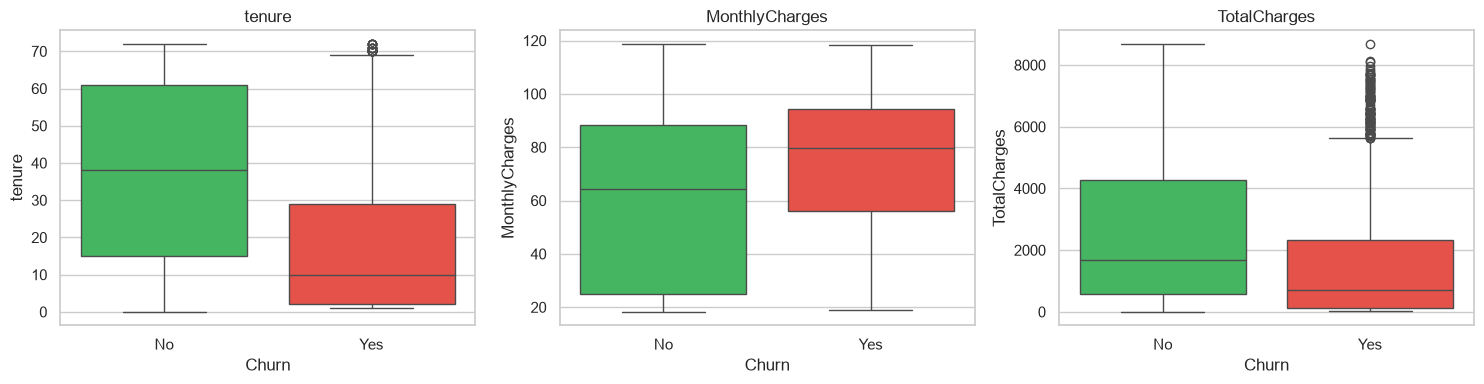

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette=CHURN_COLORS, legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [21]:
# Antigüedad en rangos de 12 meses
df["tenure_group"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"],
)
churn_rate_by("tenure_group").sort_index()

,clientes,churn_rate
tenure_group,,
0-12 meses,2186,47.4
13-24 meses,1024,28.7
25-48 meses,1594,20.4
49-72 meses,2239,9.5


> **Nota de Bryan (criterio):** Agrupé la antigüedad en rangos de 12 meses porque coincide con la duración de los contratos (mes a mes, un año, dos años) y es fácil de explicar en la web y en el dashboard ("el primer año es el más riesgoso"). Pienso que el dashboard debería usar estos mismos rangos para que las cifras de la web y de Power BI coincidan.

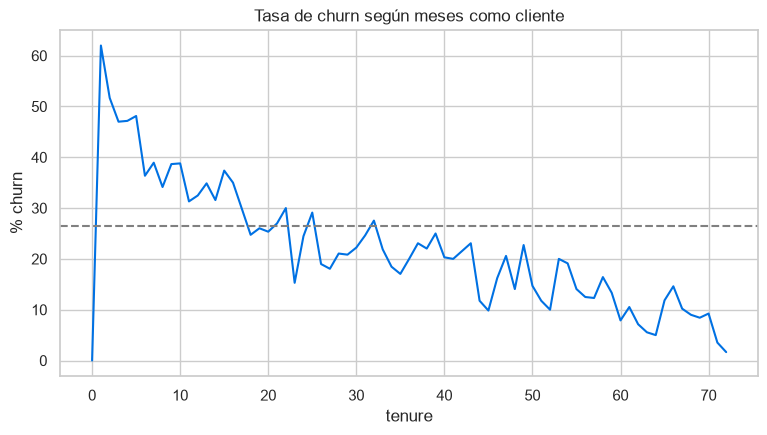

In [22]:
ax = sns.lineplot(data=df.groupby("tenure")["churn_flag"].mean().mul(100), color=BLUE)
ax.axhline(overall_rate * 100, ls="--", color="gray")
ax.set_title("Tasa de churn según meses como cliente"); ax.set_ylabel("% churn")
plt.show()

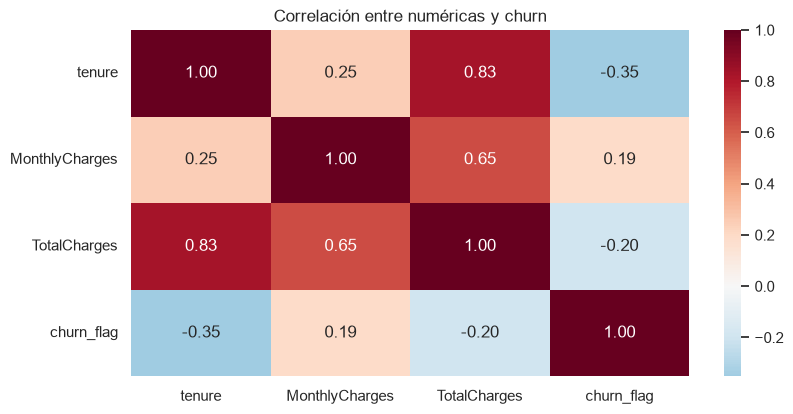

In [23]:
corr = df[NUMERIC_COLS + ["churn_flag"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación entre numéricas y churn")
plt.show()

> **Nota de Bryan (criterio):** `tenure` y `TotalCharges` están muy correlacionadas (0.83), porque el total es básicamente antigüedad × cargo mensual. Pienso que para K-Means no conviene usar las dos juntas, porque sería contar dos veces la antigüedad y los grupos saldrían cargados hacia esa variable. Mi sugerencia para el equipo de Modelos es segmentar con `tenure`, `MonthlyCharges` y `Contract` (escaladas), que son las que más separan el churn en este análisis.

## 8. Segmentos de alto riesgo

In [24]:
# Combinación de contrato e internet
pd.crosstab(df["Contract"], df["InternetService"], values=df["churn_flag"], aggfunc="mean").mul(100).round(1)

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


In [25]:
# Segmento: mes a mes + fibra óptica + 12 meses o menos
high_risk = df[(df["Contract"] == "Month-to-month")
               & (df["InternetService"] == "Fiber optic")
               & (df["tenure"] <= 12)]
print(f"Clientes en el segmento: {len(high_risk):,} ({len(high_risk) / len(df):.1%} del total)")
print(f"Tasa de churn del segmento: {high_risk['churn_flag'].mean():.1%}")

Clientes en el segmento: 916 (13.0% del total)
Tasa de churn del segmento: 70.2%


In [26]:
# Servicios de protección: ¿tener soporte o seguridad baja el churn? (solo clientes con internet)
with_internet = df[df["InternetService"] != "No"]
for col in ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection"]:
    rates = with_internet.groupby(col)["churn_flag"].mean().mul(100).round(1)
    print(f"{col}: {rates.to_dict()}")

OnlineSecurity: {'No': 41.8, 'Yes': 14.6}
TechSupport: {'No': 41.6, 'Yes': 15.2}
OnlineBackup: {'No': 39.9, 'Yes': 21.5}
DeviceProtection: {'No': 39.1, 'Yes': 22.5}


> **Nota de Bryan (criterio):** Comparé los servicios de protección **solo entre clientes con internet**, porque si incluyo a los que no tienen internet (que se van muy poco, 7.4%) la comparación queda injusta. Ojo: esto muestra relación, no causa. No podemos asegurar que regalar soporte técnico retenga al cliente; puede ser que los clientes más comprometidos son los que lo contratan. Pienso que en la web y en la presentación debemos decirlo como "se relaciona con" y no como "causa".

## 9. Impacto en ingresos

In [27]:
monthly_total = df["MonthlyCharges"].sum()
monthly_lost = df.loc[df["churn_flag"] == 1, "MonthlyCharges"].sum()
print(f"Ingreso mensual total:   US${monthly_total:,.0f}")
print(f"Ingreso mensual perdido: US${monthly_lost:,.0f} ({monthly_lost / monthly_total:.1%})")
print(f"Ingreso anual perdido:   US${monthly_lost * 12:,.0f}")

df.groupby("Churn")["MonthlyCharges"].mean().round(2)

Ingreso mensual total:   US$456,117
Ingreso mensual perdido: US$139,131 (30.5%)
Ingreso anual perdido:   US$1,669,570


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

> **Nota de Bryan (criterio):** El ingreso anual perdido (cargo mensual × 12) es una **estimación**: supone que esos clientes habrían seguido pagando lo mismo todo el año. Pienso que en la presentación debemos decir "aproximadamente" para no exagerar la cifra.

## 10. Conclusiones y propuestas para el equipo

### Comprobación de las cifras

Las cifras preliminares que publicó el equipo Web en `docs/plan-api-web.md` salieron del dataset original. Si mis cálculos dan lo mismo, los dos análisis se confirman entre sí.

In [28]:
segment_rate = high_risk["churn_flag"].mean() * 100
contract_rates = churn_rate_by("Contract")["churn_rate"]
checks = {
    "Churn general (26.5%)": (round(overall_rate * 100, 1), 26.5),
    "Ingreso mensual perdido (US$139,131)": (round(monthly_lost), 139131),
    "Ingreso mensual total (US$456,117)": (round(monthly_total), 456117),
    "Churn mes a mes (42.7%)": (contract_rates["Month-to-month"], 42.7),
    "Churn dos años (2.8%)": (contract_rates["Two year"], 2.8),
    "Segmento de alto riesgo (70.2%)": (round(segment_rate, 1), 70.2),
}
for name, (mine, reference) in checks.items():
    assert mine == reference, f"{name}: obtuve {mine}, el plan dice {reference}"
    print(f"OK  {name}: {mine}")

OK  Churn general (26.5%): 26.5
OK  Ingreso mensual perdido (US$139,131): 139131
OK  Ingreso mensual total (US$456,117): 456117
OK  Churn mes a mes (42.7%): 42.7
OK  Churn dos años (2.8%): 2.8
OK  Segmento de alto riesgo (70.2%): 70.2


### Calidad de datos
- No hay duplicados ni nulos. Solo `TotalCharges` tiene 11 valores en blanco, todos de clientes con `tenure` 0, y se llenaron con 0.
- `TotalCharges` cuadra con `tenure × MonthlyCharges` (razón mediana de 1.00), así que los datos son coherentes.

### Hallazgos principales (una frase cada uno, para la web y el dashboard)
1. **El 26.5% de los clientes se fue**, y se llevó US$139,131 al mes, el 30.5% del ingreso mensual (aproximadamente US$1.67 millones al año).
2. **El contrato es el factor más fuerte:** con contrato mes a mes se va el 42.7% de los clientes, contra el 11.3% con contrato de un año y solo el 2.8% con contrato de dos años.
3. **El riesgo se concentra en el primer año:** se va el 47.4% de los clientes con 12 meses o menos, contra el 9.5% de los que llevan más de 4 años.
4. **La fibra óptica y el pago con cheque electrónico se relacionan con más bajas:** con fibra se va el 41.9% (DSL: 19.0%) y con cheque electrónico el 45.3% (pagos automáticos: alrededor del 16%).
5. **Los servicios de soporte se relacionan con menos bajas:** entre los clientes con internet, sin seguridad en línea se va el 41.8% y con ella el 14.6%. Con soporte técnico pasa lo mismo: 41.6% sin él y 15.2% con él.

**Segmento de mayor riesgo:** mes a mes + fibra óptica + 12 meses o menos. Son 916 clientes (13% del total) y se va el 70.2%.

### Propuestas de Bryan para el equipo (para discutir)
1. **Nombre del CSV limpio:** `data/processed/telco_churn_clean.csv`. Es corto, en inglés y sin espacios, como pide el README.
2. **Qué hace la limpieza:** solo convertir `TotalCharges` a número y llenar los 11 vacíos con 0. Las demás columnas, nombres y valores se quedan igual que en el original, para no romper el contrato de la API ni el Pipeline de Modelos.
3. **Script de limpieza (ya creado):** `src/cleaning/clean_data.py` hace la verificación de la sección 1, limpia `TotalCharges`, comprueba el resultado y guarda el CSV. Cualquiera puede regenerarlo con `python src/cleaning/clean_data.py`.
4. **Para Modelos:** estratificar el split, evaluar con recall/F1 y, para K-Means, probar con `tenure`, `MonthlyCharges` y `Contract` escaladas.
5. **Para la web y el dashboard:** usar los mismos rangos de antigüedad (de 12 en 12 meses) y hablar de "relación", no de "causa".